In [3]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from collections import Counter
from itertools import combinations, permutations

1.a

In [1]:
def deterministic_lotka_volterra(p_1_o, p_2_o, alpha, beta, gamma, delta, t_max, dt):
    """
    simulates the L-V predator-prey model using Euler's integration
    follows methods from sir in class 13 notebook

    Parameters:
    p_1_o: Initial prey population.
    p_2_o: Initial predator population.
    alpha: Prey reproduction rate.
    beta: Predation rate.
    gamma: Predator death rate.
    delta: Predator growth rate given food.
    t_max: Final time of the simulation (simulation runs from t=0 to t=t_max).
    dt: Time step size.

    The populations evolve according to:
        - dp_1/dt = alpha * p_1 - beta * p_1 * p_2
        - dp_2/dt = delta * p_1 * p_2 - gamma * p_2
    """

    # Number of steps needed to go from t=0 to t=t_max
    n_steps = int(round(t_max / dt))

    # arrays for storing time and populations at each time step
    t = np.linspace(0, t_max, n_steps + 1)
    p_1 = np.zeros(n_steps + 1)
    p_2 = np.zeros(n_steps + 1)
    p_1[0] = p_1_o
    p_2[0] = p_2_o

    # Euler update taken from Sayama, predator-prey-continuous.py, see .tex for cite
    # with variables renamed: x -> p_1, y -> p_2, a/b/c/d -> alpha/beta/gamma/delta, Dt -> dt.
    for i in range(n_steps):
        # Prey: reproduction minus predation
        p_1[i+1] = p_1[i] + (alpha * p_1[i] - beta * p_1[i] * p_2[i]) * dt

        # Predators: growth from eating prey minus death
        p_2[i+1] = p_2[i] + (delta * p_1[i] * p_2[i] - gamma * p_2[i]) * dt

    return t, p_1, p_2

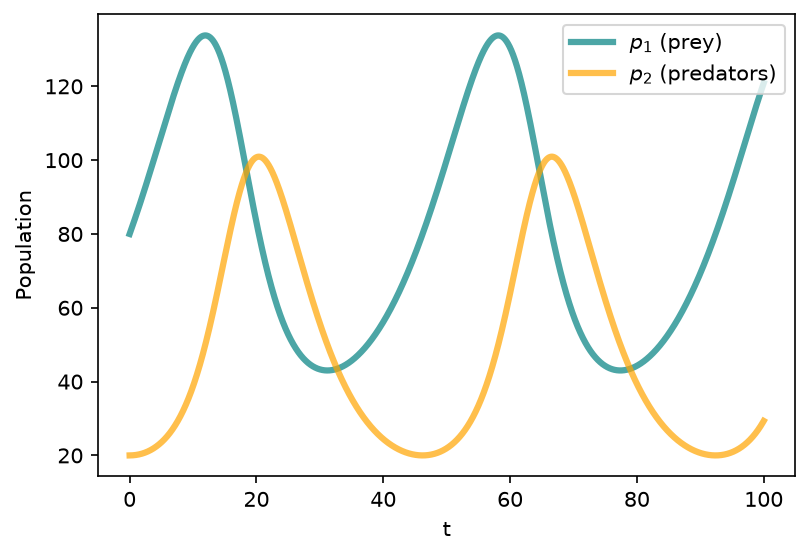

In [4]:
alpha, beta, gamma, delta = 0.1, 0.002, 0.2, 0.0025
p_1_o, p_2_o = 80, 20 # initial prey, predators
t_max, dt = 100, 0.0001

t, p_1, p_2 = deterministic_lotka_volterra(p_1_o, p_2_o, alpha, beta, gamma, delta, t_max, dt)

fig, ax = plt.subplots(1,1,figsize=(6,4),dpi=150)
ax.plot(t, p_1, c="teal", lw=3, alpha=0.7, label=r'$p_1$ (prey)')
ax.plot(t, p_2, c="orange", lw=3, alpha=0.7, label=r'$p_2$ (predators)')

ax.set_xlabel('t')
ax.set_ylabel('Population')
ax.legend()

plt.show()